# Laboratorio 1: propagación hacia adelante (EST852, Redes Neuronales I)

**Duración estimada de la parte práctica:** 35 min (la Parte 6 es opcional y queda fuera de la clase).

**Objetivos**

1. Calcular a mano (con NumPy) la propagación hacia adelante de una red, con la notación de la clase: $Z^{[l]}=W^{[l]T}A^{[l-1]}+b^{[l]}$, $A^{[l]}=g(Z^{[l]})$.
2. Verificar con el XOR que una capa oculta con activación no lineal resuelve lo que un modelo lineal no puede.
3. Implementar activaciones, sus derivadas y la entropía cruzada.
4. Comprobar que tu propagación hacia adelante reproduce `predict_proba` de `MLPClassifier`.
5. (Opcional) Explorar el teorema de aproximación universal y sus límites.

**Cómo trabajar.** Las celdas con `...` son las que debes completar. Después de cada una hay una celda de verificación que muestra ✅ o ❌. No avances si ves ❌.

**Convención de este curso:** las matrices de datos son *características × observaciones* ($X\in\mathbb{R}^{n\times m}$). scikit-learn usa *observaciones × características*, por eso aparecerá `X.T`.

In [1]:
import numpy as np, sklearn
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss
import warnings; warnings.filterwarnings('ignore')

print('numpy', np.__version__, '| scikit-learn', sklearn.__version__)
np.set_printoptions(precision=4, suppress=True)

def verificar(nombre, condicion):
    """Muestra ✅/❌. 'condicion' es una función sin argumentos que devuelve True/False."""
    try:
        ok = bool(condicion())
    except Exception:
        ok = False
    print(('✅ ' if ok else '❌ ') + nombre)

numpy 2.5.3 | scikit-learn 1.9.1


## Parte 1. NumPy en 5 minutos (5 min)

Solo se necesitan tres herramientas: el producto matricial `@`, la transpuesta `.T` y el *broadcasting* (un vector columna se suma a todas las columnas).

In [2]:
W = np.array([[1, 2, 3],
              [4, 5, 6]])            # 2 x 3
x = np.array([[1], [0], [2]])        # 3 x 1
b = np.array([[10], [20]])           # 2 x 1

print('W @ x       ->', (W @ x).shape)
print('W @ x + b   ->', (W @ x + b).shape)
print((W @ x + b).ravel())
print('W.T         ->', W.T.shape)

W @ x       -> (2, 1)
W @ x + b   -> (2, 1)
[17 36]
W.T         -> (3, 2)


**Ejercicio 1.1.** En la red $2\to3\to1$ de la clase, $W^{[1]}$ es $2\times3$ y $X$ es $2\times4$ (4 observaciones). Calcula $Z^{[1]}=W^{[1]T}X+b^{[1]}$.

In [3]:
rng = np.random.default_rng(0)
W1 = rng.normal(size=(2, 3))
b1 = rng.normal(size=(3, 1))
X  = rng.normal(size=(2, 4))

Z1 = ...          # completar: W1^T X + b1

verificar('Z1 tiene forma (3, 4)', lambda: Z1.shape == (3, 4))
verificar('Z1 correcto', lambda: np.allclose(Z1[:, 0], W1.T @ X[:, 0] + b1[:, 0]))

❌ Z1 tiene forma (3, 4)
❌ Z1 correcto


## Parte 2. XOR: lo que un modelo lineal no puede (10 min)

Tabla de verdad: $y=1$ si exactamente una entrada vale 1.

In [4]:
Xx = np.array([[0, 0], [1, 0], [0, 1], [1, 1]])   # 4 x 2  (formato scikit-learn)
yx = np.array([0, 1, 1, 0])

lin = LogisticRegression(C=1e6).fit(Xx, yx)
print('Accuracy de la regresión logística en XOR:', lin.score(Xx, yx))

Accuracy de la regresión logística en XOR: 0.5


Ninguna recta clasifica correctamente los 4 puntos, así que un modelo lineal acierta como máximo 3 de 4.

**Ejercicio 2.1.** Implementa la red $2\to2\to1$ de la clase (láminas 10 y 11), con pesos fijados a mano. Cada neurona oculta calcula $a^{[1]}_k=\max(\mathbf{w}_k^Tx+b^{[1]}_k,0)$:

$$a^{[1]}_1=\max(x_1+x_2,0),\quad a^{[1]}_2=\max(x_1+x_2-1,0),\quad \hat y=a^{[1]}_1-2a^{[1]}_2$$

En la notación matricial: $W^{[1]}=\begin{bmatrix}1&1\\1&1\end{bmatrix}$, $b^{[1]}=\begin{bmatrix}0\\-1\end{bmatrix}$, $W^{[2]}=\begin{bmatrix}1\\-2\end{bmatrix}$, $b^{[2]}=0$. Recuerda que aquí $X$ es *características × observaciones*.

In [5]:
X_xor = Xx.T                                  # 2 x 4  (características x observaciones)

W1 = np.array([[1, 1], [1, 1]])
b1 = np.array([[0], [-1]])
W2 = np.array([[1], [-2]])
b2 = 0

def relu(z):
    return ...                    # completar: max(z, 0) elemento a elemento

Z1 = ...                  # completar
A1 = relu(Z1)
Z2 = ...                     # completar

print('Representación oculta (columnas = observaciones):'); print(A1)
print('Salida:', Z2)

verificar('relu', lambda: np.array_equal(relu(np.array([-1., 0., 2.])), [0, 0, 2]))
verificar('La salida reproduce XOR', lambda: np.allclose(Z2, [[0, 1, 1, 0]]))

Representación oculta (columnas = observaciones):
Ellipsis
Salida: Ellipsis
❌ relu
❌ La salida reproduce XOR


**Pregunta 2.2.** Observa la matriz `A1`: ¿en qué espacio $(a^{[1]}_1,a^{[1]}_2)$ son separables las dos clases con una recta? Compáralo con la figura de la presentación.

TypeError: 'ellipsis' object is not subscriptable

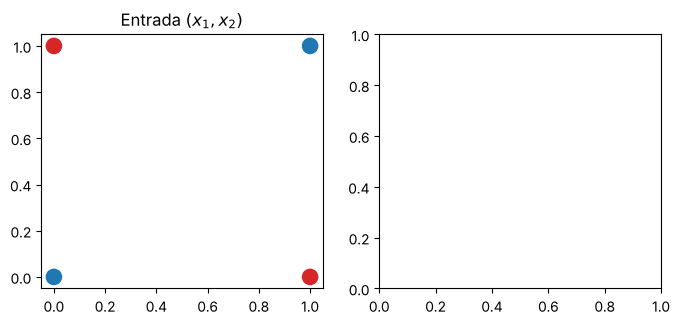

In [6]:
cols = ['tab:blue' if v == 0 else 'tab:red' for v in yx]
fig, ax = plt.subplots(1, 2, figsize=(8, 3.3))
ax[0].scatter(Xx[:, 0], Xx[:, 1], c=cols, s=120); ax[0].set_title('Entrada $(x_1,x_2)$')
ax[1].scatter(A1[0], A1[1], c=cols, s=120); ax[1].set_title('Oculto $(a^{[1]}_1,a^{[1]}_2)$')
h = np.linspace(-.2, 2.4, 10); ax[1].plot(h, (h - .5) / 2, 'k--', lw=1)
plt.tight_layout(); plt.show()

## Parte 3. Activaciones, derivadas y pérdida (10 min)

**Ejercicio 3.1.** Implementa sigmoide, tangente hiperbólica (con la fórmula de exponenciales) y softmax estable (restando el máximo de cada columna).

In [7]:
def sigmoide(z):
    return ...

def tanh_(z):
    return ...

def softmax(Z):
    # Z: K x m  (una columna por observación)
    E = np.exp(Z - Z.max(axis=0, keepdims=True))
    return ...

verificar('sigmoide(0)=0.5', lambda: np.isclose(sigmoide(0.0), 0.5))
verificar('tanh coincide con np.tanh', lambda: np.allclose(tanh_(np.linspace(-3, 3, 7)), np.tanh(np.linspace(-3, 3, 7))))
verificar('softmax([1,2,3])', lambda: np.allclose(softmax(np.array([[1.], [2.], [3.]])).ravel(), [0.0900, 0.2447, 0.6652], atol=1e-4))
verificar('softmax suma 1 por columna', lambda: np.allclose(softmax(np.random.default_rng(1).normal(size=(4, 5))).sum(axis=0), 1))
verificar('softmax estable con valores grandes', lambda: np.all(np.isfinite(softmax(np.array([[1000.], [1001.]])))))

❌ sigmoide(0)=0.5
❌ tanh coincide con np.tanh
❌ softmax([1,2,3])
❌ softmax suma 1 por columna
❌ softmax estable con valores grandes


**Ejercicio 3.2.** Implementa las derivadas de la sigmoide y de la tangente hiperbólica, y verifícalas con diferencias centrales:

$$\sigma'(z)=\sigma(z)\,(1-\sigma(z)),\qquad \tanh'(z)=1-\tanh^2(z)$$

Estas derivadas se usan en el descenso por gradiente (lámina 29) y se aplicarán en el Laboratorio 2.

In [8]:
def dsigmoide(z):
    s = sigmoide(z)
    return ...

def dtanh(z):
    return ...

def derivada_numerica(f, z, eps=1e-6):
    return (f(z + eps) - f(z - eps)) / (2 * eps)

zs = np.linspace(-4, 4, 9)
verificar('dsigmoide', lambda: np.allclose(dsigmoide(zs), derivada_numerica(sigmoide, zs), atol=1e-8))
verificar('dtanh', lambda: np.allclose(dtanh(zs), derivada_numerica(np.tanh, zs), atol=1e-8))
print('máximo de sigma\'(z):', dsigmoide(zs).max(), '(en z = 0)')

❌ dsigmoide
❌ dtanh


AttributeError: 'ellipsis' object has no attribute 'max'

**Ejercicio 3.3.** Implementa la entropía cruzada binaria. Para $A,Y\in\mathbb{R}^{1\times m}$:

$$J=-\frac1m\sum_{i=1}^{m}\left[y^{(i)}\log a^{(i)}+\bigl(1-y^{(i)}\bigr)\log\bigl(1-a^{(i)}\bigr)\right]$$

In [9]:
def costo_binario(A, Y):
    return ...

A = np.array([[0.9, 0.2, 0.7, 0.4]]); Y = np.array([[1, 0, 1, 1]])
verificar('coincide con sklearn.log_loss', lambda: np.isclose(costo_binario(A, Y), log_loss(Y.ravel(), A.ravel())))
verificar('con a=0.5 el costo es ln 2', lambda: np.isclose(costo_binario(np.array([[.5, .5]]), np.array([[1, 0]])), np.log(2)))
print('J =', costo_binario(A, Y))

❌ coincide con sklearn.log_loss
❌ con a=0.5 el costo es ln 2
J = Ellipsis


**Pregunta 3.4.** ¿Qué valor toma el costo si la red predice siempre $a=0{,}5$? ¿Qué significa ese valor para la clasificación? (Esto reaparece en el Laboratorio 2.)

## Parte 4. Tu forward frente a scikit-learn (5 min)

Entrenamos un `MLPClassifier` $2\to3\to1$ con activación sigmoide y reproducimos `predict_proba` usando solo sus matrices `coefs_` e `intercepts_`.

En scikit-learn, `coefs_[l]` tiene forma $n_{l-1}\times n_l$, igual que $W^{[l]}$.

In [10]:
X, y = make_moons(300, noise=0.25, random_state=0)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

mlp = MLPClassifier(hidden_layer_sizes=(3,), activation='logistic', solver='lbfgs',
                    max_iter=5000, random_state=0).fit(Xtr, ytr)
print('formas de coefs_:', [c.shape for c in mlp.coefs_], '| intercepts_:', [b.shape for b in mlp.intercepts_])

formas de coefs_: [(2, 3), (3, 1)] | intercepts_: [(3,), (1,)]


**Ejercicio 4.1.** Completa `forward`. Recibe $X$ como *características × observaciones* y devuelve $A^{[2]}$ de forma $1\times m$.

In [11]:
def forward(X, W1, b1, W2, b2):
    Z1 = ...
    A1 = sigmoide(Z1)
    Z2 = ...
    A2 = sigmoide(Z2)
    return A2

W1, W2 = mlp.coefs_
b1 = mlp.intercepts_[0].reshape(-1, 1)      # vector columna 3 x 1
b2 = mlp.intercepts_[1].reshape(-1, 1)      # 1 x 1

p_mio = forward(Xte.T, W1, b1, W2, b2).ravel()      # Xte.T: características x observaciones
p_sk  = mlp.predict_proba(Xte)[:, 1]

print('diferencia máxima:', np.abs(p_mio - p_sk).max())
verificar('Mi forward reproduce predict_proba', lambda: np.allclose(p_mio, p_sk, atol=1e-10))

AttributeError: 'ellipsis' object has no attribute 'ravel'

## Parte 5. Capas ocultas y frontera de decisión (10 min)

Compara una regresión logística con MLP de 1, 3 y 20 neuronas ocultas sobre *moons* (210 observaciones de entrenamiento y 90 de prueba).

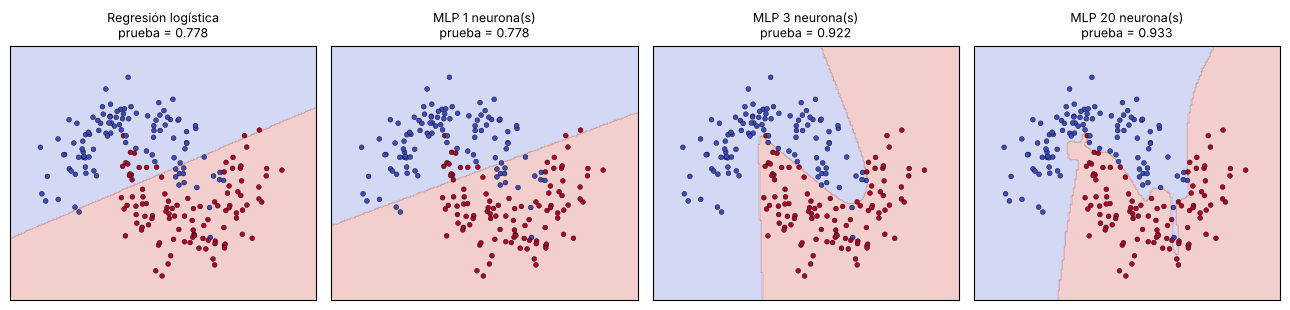

{'Regresión logística': 0.778, 'MLP 1 neurona(s)': 0.778, 'MLP 3 neurona(s)': 0.922, 'MLP 20 neurona(s)': 0.933}


In [12]:
xx, yy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200)); G = np.c_[xx.ravel(), yy.ravel()]

modelos = {'Regresión logística': LogisticRegression().fit(Xtr, ytr)}
for h in (1, 3, 20):
    modelos[f'MLP {h} neurona(s)'] = MLPClassifier((h,), activation='logistic', solver='lbfgs',
                                                    max_iter=5000, random_state=0).fit(Xtr, ytr)
fig, ax = plt.subplots(1, 4, figsize=(13, 3.2))
for a, (nombre, m) in zip(ax, modelos.items()):
    a.contourf(xx, yy, m.predict(G).reshape(xx.shape), alpha=.25, cmap='coolwarm')
    a.scatter(Xtr[:, 0], Xtr[:, 1], c=ytr, cmap='coolwarm', s=12, edgecolor='k', lw=.3)
    a.set_title(f'{nombre}\nprueba = {m.score(Xte, yte):.3f}', fontsize=9); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
print({k: round(m.score(Xte, yte), 3) for k, m in modelos.items()})

**Preguntas 5.1.**

1. ¿Por qué el MLP de 1 neurona oculta se comporta como un modelo lineal? (Pista: ¿qué forma tiene la frontera $a^{[2]}=0{,}5$ si $a^{[1]}$ es una sola función sigmoide de una combinación lineal de $x$?)
2. Con 90 observaciones de prueba, ¿cuántos puntos porcentuales vale una observación? ¿Son concluyentes las diferencias entre 3 y 20 neuronas?
3. Resuelve el XOR con `MLPClassifier` de 2 neuronas y `solver='lbfgs'`. ¿Siempre converge a la solución con distintos `random_state`? (Pruébalo con 10 semillas.)

In [13]:
aciertos = 0
for rs in range(10):
    m = MLPClassifier((2,), activation='relu', solver='lbfgs', max_iter=2000, random_state=rs).fit(Xx, yx)
    aciertos += (m.score(Xx, yx) == 1.0)
print(f'Semillas con accuracy 1.0 en XOR: {aciertos} de 10')

Semillas con accuracy 1.0 en XOR: 3 de 10


## Parte 6 (opcional). Aproximación universal y sus límites

El teorema de aproximación universal (lámina 23) dice que una red con una capa oculta no lineal y suficientes neuronas aproxima cualquier función continua en un compacto. Aquí lo exploras con $f(x)=\sin(2\pi x)$ en $[0,1]$ y activación $\tanh$.

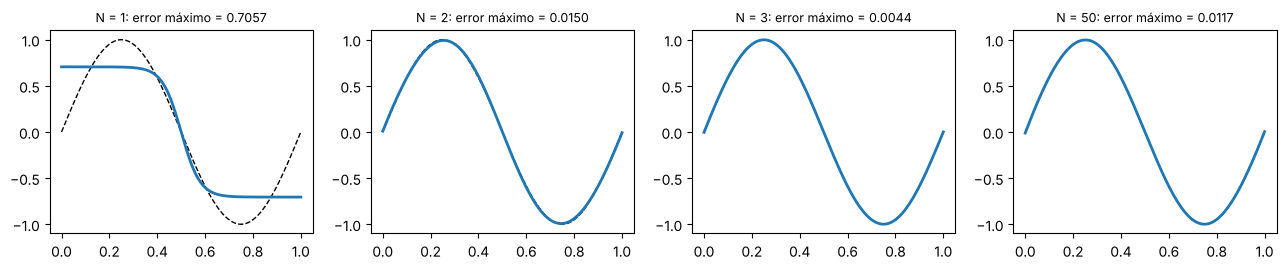

In [14]:
from sklearn.neural_network import MLPRegressor

f = lambda x: np.sin(2 * np.pi * x)
x = np.linspace(0, 1, 60).reshape(-1, 1); y = f(x).ravel()
xg = np.linspace(0, 1, 500).reshape(-1, 1)

def ajustar(N, X, Y, rs=0):
    return MLPRegressor(hidden_layer_sizes=(N,), activation='tanh', solver='lbfgs',
                        max_iter=20000, tol=1e-10, random_state=rs).fit(X, Y)

fig, ax = plt.subplots(1, 4, figsize=(13, 2.8))
for a, N in zip(ax, (1, 2, 3, 50)):
    m = ajustar(N, x, y)
    err = np.abs(m.predict(xg) - f(xg).ravel()).max()
    a.plot(xg, f(xg), 'k--', lw=1); a.plot(xg, m.predict(xg), lw=2)
    a.set_title(f'N = {N}: error máximo = {err:.4f}', fontsize=9)
plt.tight_layout(); plt.show()

**Pregunta 6.1.** ¿Qué pasa con una sola neurona oculta? ¿Disminuye siempre el error al aumentar $N$?

**Ejercicio 6.2.** Ahora la muestra es pequeña y ruidosa (25 observaciones). Compara el error de entrenamiento con el error respecto de la función verdadera para $N=3$ y $N=100$.

In [15]:
rng = np.random.default_rng(0)
xs = rng.uniform(0, 1, 25).reshape(-1, 1); ys = f(xs).ravel() + rng.normal(0, .3, 25)
for N in (3, 100):
    m = ajustar(N, xs, ys)
    ecm_train = np.mean((m.predict(xs) - ys) ** 2)
    ecm_f = np.mean((m.predict(xg) - f(xg).ravel()) ** 2)
    print(f'N = {N:3d} | ECM en la muestra = {ecm_train:.4f} | ECM respecto de f = {ecm_f:.4f}')

N =   3 | ECM en la muestra = 0.0529 | ECM respecto de f = 0.0279


N = 100 | ECM en la muestra = 0.0377 | ECM respecto de f = 0.0895


**Pregunta 6.3.** El teorema garantiza que existe una red con error pequeño sobre $f$. ¿Por qué aquí el error respecto de $f$ no mejora con $N=100$?

## Cierre

- Con $W^{[l]}\in\mathbb{R}^{n_{l-1}\times n_l}$ y datos en columnas, la propagación hacia adelante es $Z^{[l]}=W^{[l]T}A^{[l-1]}+b^{[l]}$.
- La capa oculta con activación no lineal aprende una representación donde las clases son separables.
- Sin activación no lineal, la red equivale a un modelo lineal.
- Una capa oculta no lineal basta para aproximar cualquier función continua, pero eso no garantiza cuántas neuronas hacen falta, que el entrenamiento las encuentre ni que la red generalice (Parte 6, opcional).
- La entropía cruzada binaria es la log-verosimilitud negativa; con $a=0{,}5$ vale $\ln 2$.

**Laboratorio 2:** backpropagation, verificación del gradiente, entrenamiento y comparación con la SVM.